# Automatic differentiation in *refnx*

With version 0.1.64 *refnx* onwards there is a capability to use the [JAX](https://docs.jax.dev/en/latest/index.html) library to carry out automatic differentiation of various parts of a modelling system. This is used when [sampling with NUTS](https://refnx.readthedocs.io/en/latest/pymc_lipid_sampling.html). Using the automatic differentiation functionality requires that `jax` be installed.

The approach is to transform *refnx* objects, such as: `Objective`, `ReflectModel`, into an Intermediate Representation (IR) that is suitable for use with Automatic Differentiation (AD).

In [1]:
# this import is required at the top to make sure the JAX library uses 64-bit during the reflectivity calculation.
import os

os.environ["JAX_ENABLE_X64"] = "1"

In [2]:
from pathlib import Path
from functools import partial
import numpy as np
import matplotlib.pyplot as plt
import jax
from scipy.optimize._numdiff import approx_derivative
import jax.numpy as jnp
from jax import grad

import refnx

# this is the module that has all the extra bits we need.
from refnx.reflect.extra import (
    compile_objective,
    make_scipy_objective,
    compile_model,
)
from refnx.reflect import SLD, ReflectModel
from refnx.dataset import Data1D
from refnx.analysis import Objective, Parameter
from refnx.reflect._jax_reflect import jax_smeared_kernel_pointwise, jabeles
from refnx.reflect.reflect_model import reflectivity

Setup the model/objective as normal.

In [3]:
pth = Path(refnx.__file__).parent
pth = pth / "analysis" / "tests"

# the data
data = Data1D(pth / "e361r.txt")

# a system with:
# Si | SiO2 | polymer | d2o

# create the SLDs
si = SLD(2.07)
sio2 = SLD(3.47)
polymer = SLD(1.0)
d2o = SLD(6.36)

# create thickness/roughness parameters
t1 = Parameter(15, bounds=(0, 20))
r1 = Parameter(3, bounds=(0, 10))

t2 = Parameter(150, bounds=(100, 300))
r2 = Parameter(3, bounds=(0, 10))
vf = Parameter(0.2, bounds=(0, 1))

# create the polymer slab
pfilm = polymer(t2, r2, vfsolv=vf)

r3 = Parameter(3, bounds=(0, 10))

# create the structure
structure = si | sio2(t1, r1) | pfilm | d2o(0, r3)

model = ReflectModel(
    structure, dq_type="pointwise", dq=5.0, bkg=1e-5, quad_order=17
)

r1.setp(vary=True, bounds=(1, 10))
r2.setp(vary=True, bounds=(1, 10))
r3.setp(vary=True, bounds=(1, 10))

t1.setp(vary=True, bounds=(1, 30))
t2.setp(vary=True, bounds=(100, 300))
vf.setp(vary=True, bounds=(0, 1))
polymer.real.setp(vary=True, bounds=(0.5, 2))


model.bkg.setp(vary=True, bounds=(1e-5, 5e-5))
model.scale.setp(vary=True, bounds=(0.9, 1.1))

data.x_err = 0.05 * data.x

objective = Objective(model, data)

# the parameters in the model
vp0 = np.array(model.parameters.varying_parameters())
# the parameters contained within the objective as well
op0 = np.array(objective.parameters.varying_parameters())

Up until this point everything is as we would normally do. Let's carry out a demonstration of the automatic differentiation functionality.

## Differentiating the forward model

In [4]:
# cm is a `CompiledModel` object
cm = compile_model(model)

(1001,)


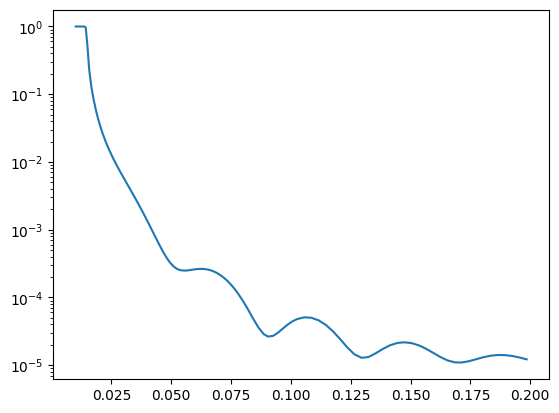

In [5]:
# `CompiledModel.model` calculates the forward model.
# if you provide data.x_err you get a resolution smeared version
# if you omit the last argument there's no resolution smearing.
y = cm.model(data.x, vp0, data.x_err)
plt.plot(data.x, y)
plt.yscale("log")

# check that the JAX calculated model is the same as the 'normal' refnx calculation
np.testing.assert_allclose(y, model(data.x, vp0, x_err=data.x_err))

# Note: you can supply x and x_err arrays of arbitrary length. They don't have to come from a dataset
x = np.geomspace(0.01, 0.02, 1001)
x_err = 0.05 * x
print(cm.model(x, vp0, x_err).shape)

### Jacobian of the forward model

The jacobian is the partial derivative of the reflectivity with respect to each of the parameters.

In [6]:
# `CompiledModel.jacfwd` calculates the jacobian.
# For a model with N points and P free parameters the shape of the jacobian should be (N, P).
# For a given point N there are P partial derivatives.
# Here there are 99 data points and 9 free parameters.
jac = cm.jacfwd(data.x, vp0, data.x_err)
print(jac.shape)
assert cm.n_free == jac.shape[-1]

(99, 9)


In [7]:
# we can also differentiate the forward model ourselves.
# argnums says we want to be differentiating R w.r.t the parameters.
my_jac_fn = jax.jacobian(cm.model, argnums=1)
jac = my_jac_fn(data.x, vp0, data.x_err)
print(jac.shape)

(99, 9)


### Compare the jacobian to that estimated by numerical differentiation (scipy)

The values calculated by automatic differentiation are much more accurate

In [8]:
# For `model(x, vp0)` we need to freeze the x values to differentiate against vp0
pf = partial(model, data.x)

numdiff_jac = approx_derivative(pf, vp0)
np.testing.assert_allclose(numdiff_jac, jac, atol=4e-3)

## Differentiating the *Objective*

In [9]:
# co is a `CompiledObjective` object
co = compile_objective(objective)

In [10]:
# `CompiledObjective.logl` gives the log-likelihood of the objective.
# compare to the Objective.logl method.
co.logl(op0), objective.logl(op0)

(-8748.020510037062, np.float64(-8748.020510037064))

### Gradient of the log-likelihood

The gradient is the partial derivative of the log-likelihood with respect to each parameter

In [11]:
# `CompiledObjective.grad_logl` calculates the gradient
co.grad_logl(op0)

Array([ 1.69873824e+04,  1.10831986e+08, -8.02126522e+01, -1.18466386e+01,
       -3.84637995e+01, -4.20016193e+03,  2.93147048e+00, -2.81410849e+04,
       -1.31310381e+02], dtype=float64)

In [12]:
# compare to the numerical differentiation estimation with finite differences
np.testing.assert_allclose(
    co.grad_logl(op0), approx_derivative(objective.logl, op0)
)

### Hessian of the log-likelihood

The Hessian is the second derivative of the log-likelihood with respect to the parameters.

In [13]:
# all we have to do is differentiate the gradient (1st derivative)
hf = jax.jacobian(co.grad_logl)

In [14]:
hf(op0)

Array([[-1.81172204e+05, -1.01613354e+08, -3.25605716e+02,
         2.89120217e+00, -8.31882188e+01,  9.16876470e+03,
         3.48530830e+01,  6.14307235e+04,  1.28476259e+02],
       [-1.01613354e+08, -1.12059446e+13, -1.26308971e+06,
         1.20242461e+06,  3.27331409e+04,  4.22130658e+07,
         1.21264705e+06,  2.82827541e+08,  7.40354857e+06],
       [-3.25605716e+02, -1.26308971e+06, -6.57017758e+00,
         7.07898363e-02, -3.40553609e+00,  1.05745865e+02,
         2.28331744e-01,  7.08497298e+02,  4.48821523e+00],
       [ 2.89120217e+00,  1.20242461e+06,  7.07898363e-02,
        -3.38864543e+00, -9.40604823e-02, -5.00145164e-01,
         9.50933502e-02, -3.35097260e+00, -1.19319227e+00],
       [-8.31882188e+01,  3.27331409e+04, -3.40553609e+00,
        -9.40604823e-02, -1.60904847e+00,  1.57509391e+01,
         3.30424814e-01,  1.05531292e+02,  8.04571779e-01],
       [ 9.16876470e+03,  4.22130658e+07,  1.05745865e+02,
        -5.00145164e-01,  1.57509391e+01, -4.728906

In [15]:
# compare to the hessian calculated by numerical differentiation
np.testing.assert_allclose(
    hf(op0), approx_derivative(co.grad_logl, op0), rtol=5e-7
)